# Telling harvest from stress

### Cycle-aware irrigation screening for centre-pivot farms in Wadi as-Sirhan

**Team Beyond Earth** — Arab Youth Space Hackathon 2026, 813 Challenge
Theme 02, Precision Agriculture & Crop Intelligence

---

Alfalfa in Al Jouf is cut roughly every thirty days. Every cut drops a field's NDVI from
about 0.90 to about 0.35 within ten days, so a season of per-field NDVI here is a **sawtooth**,
not a trend — and on any date a large share of fields are mid-cut and read exactly like severe
water stress. Ranking fields by NDVI decline therefore ranks *harvest*, not stress.

On 22 July 2026, **51 of 328** detected pivots were mid-cut. A decline ranking would have put
every one of them at the top of an irrigation queue.

This notebook rebuilds every number in the submission from open archives:

1. Sentinel-2 search, mosaicking by solar day, and cloud screening
2. Centre-pivot detection by shape, at peak greenness
3. The season-long per-field NDVI series
4. EMIT hyperspectral download, band selection and orthorectification
5. The prediction contest that tested whether narrow bands beat NDVI — and the
   leave-one-scene-out check that overturned the result
6. The data file the dashboard and API read

**Credentials.** Sentinel-2 needs none; it is served anonymously, and it is where every number
the dashboard shows comes from. NASA EMIT needs a free Earthdata login and is **optional** —
supply `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` by whichever route this host offers
(Kaggle Secrets, Colab Secrets via the key icon in the left sidebar with notebook access on,
plain environment variables, or a `~/.netrc`) and the hyperspectral section runs. Leave them
out and it is skipped cleanly: the notebook says what it is skipping and still writes every
output file. Nothing here prompts for a password — inside a **Run all**, a blocking prompt is
indistinguishable from a crashed run, and nothing is written to disk.

**If the run stalls with no output.** Some networks refuse the AWS bucket that holds the
imagery. Set `SOURCE = "planetary"` in the constants cell to read the same Copernicus product
from Microsoft Planetary Computer instead.

Runtime: about 7 minutes end to end on a datacentre connection, plus roughly 15 minutes and
3 GB per EMIT granule if the hyperspectral section runs. On a home connection, longer — the
run is bound by download speed, not compute.

# Beyond Earth — does hyperspectral actually add anything?

**The question this notebook answers.** On a single day a farmer cannot tell a freshly cut alfalfa field
from a water-stressed one: both have lost their canopy and both read low in NDVI. Ten days later the cut
field is green again and the stressed field is not. If we can tell them apart **on the day**, irrigation
goes to the field that needs it instead of the field that was simply mown.

**Why the first attempt did not settle it.** One EMIT scene gave 25 cut fields and 3 stressed ones, and the
cut/stressed labels were themselves read off NDVI — so every index looked like it worked, NDVI included.
Three points decide nothing and a label made of NDVI cannot be used to show NDVI failing.

**What is different here.**

1. **Many scenes, not one.** Every EMIT granule over Tabarjal whose date has a Sentinel-2 scene beside it.
2. **The label comes from the future, the predictors from the present.** A field is scored on what its NDVI
   does 15–45 days *after* the hyperspectral measurement. Nothing in the predictor set can see that.
3. **Only the hard cases.** Rows are restricted to fields already low on the measurement day — the ones a
   farmer genuinely cannot call. Separating a green field from a bare one is not a skill worth paying for.
4. **A prediction contest, not a p-value.** NDVI alone versus NDVI plus the narrow bands, compared by
   cross-validated AUC over repeated splits. If the narrow bands add nothing, the two curves sit on top of
   each other and we say so.

The result at the end is whatever it is. Section 11 prints it without interpretation.

## 1 · Install

In [1]:
import subprocess, sys
pkgs = ["odc-stac", "pystac-client", "earthaccess", "rasterio", "geopandas",
        "scikit-image", "scikit-learn", "h5netcdf", "h5py", "dask[array]",
        "planetary-computer"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + pkgs, check=False)
print("installed")

installed


## 2 · Configuration

In [2]:
import numpy as np, pandas as pd, xarray as xr, os, gc, json, warnings
warnings.filterwarnings("ignore")

AOI        = [38.15, 29.75, 38.85, 30.30]      # W, S, E, N - Tabarjal, Al Jouf, KSA
UTM        = "EPSG:32637"
RES_FIELD  = 20                                 # metres, for detecting the pivots
RES_TS     = 60                                 # metres, for the season-long NDVI series
PX_HA      = (RES_FIELD * RES_FIELD) / 10_000

SEASON     = ("2026-02-01", "2026-09-08")       # wide enough to give every EMIT date a future window
MAX_CLOUD_S2   = 20
MAX_CLOUD_EMIT = 20

MIN_HA, MAX_HA = 10, 400
LOW, HIGH      = 0.45, 0.70                     # the same thresholds as the first run
FUTURE_MIN, FUTURE_MAX = 15, 45                 # days after the EMIT date that decide the label
MATCH_DAYS     = 2                              # EMIT date must sit within this many days of a S2 date
MAX_GRANULES   = 8                              # each one is a ~3 GB download

# Where the Sentinel-2 scenes come from. Both serve the same Copernicus L2A
# product; they differ only in who hosts the bytes. Switch to "planetary" if the
# network you are running on cannot reach the AWS bucket.
#   earthsearch -> sentinel-cogs.s3.us-west-2.amazonaws.com   (Element 84)
#   planetary   -> sentinel2l2a01.blob.core.windows.net       (Microsoft)
SOURCE = "planetary"

print("AOI", AOI, "| season", SEASON[0], "->", SEASON[1], "| source", SOURCE)

AOI [38.15, 29.75, 38.85, 30.3] | season 2026-02-01 -> 2026-09-08 | source planetary


## 3 · Earthdata credentials

From Colab Secrets, so a run can never stall on a hidden `input()` prompt again.

In [3]:
import os

def _load_earthdata():
    """Populate EARTHDATA_USERNAME / EARTHDATA_PASSWORD from whichever
    secret store this environment has. Never prompts - a blocking input()
    inside Run All is indistinguishable from a crashed run."""
    if os.environ.get("EARTHDATA_USERNAME") and os.environ.get("EARTHDATA_PASSWORD"):
        return "environment"
    try:                                          # Kaggle
        from kaggle_secrets import UserSecretsClient
        us = UserSecretsClient()
        os.environ["EARTHDATA_USERNAME"] = us.get_secret("EARTHDATA_USERNAME")
        os.environ["EARTHDATA_PASSWORD"] = us.get_secret("EARTHDATA_PASSWORD")
        return "kaggle secrets"
    except Exception:
        pass
    try:                                          # Colab
        from google.colab import userdata
        os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
        os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
        return "colab secrets"
    except Exception:
        pass
    if os.path.exists(os.path.expanduser("~/.netrc")):
        return "netrc"
    return None

CRED_SOURCE = _load_earthdata()
HAVE_EDL    = CRED_SOURCE is not None
print("earthdata credentials:", CRED_SOURCE or "NONE FOUND")
if not HAVE_EDL:
    print("  -> the hyperspectral section will be skipped. Everything the")
    print("     dashboard needs comes from Sentinel-2 and still runs.")

earthdata credentials: NONE FOUND
  -> the hyperspectral section will be skipped. Everything the
     dashboard needs comes from Sentinel-2 and still runs.


## 4 · Sentinel-2 — every usable day in the season

One Sentinel-2 pass rarely covers the whole box, so items are grouped by solar day and mosaicked.
A day is kept only if the mosaic actually covers the area.

In [4]:
import pystac_client, odc.stac
from rasterio import features
from shapely.geometry import shape

if SOURCE == "planetary":
    import planetary_computer
    CAT = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)
    BANDS = {"red": "B04", "nir": "B08", "scl": "SCL"}
else:
    CAT = pystac_client.Client.open("https://earth-search.aws.element84.com/v1")
    BANDS = {"red": "red", "nir": "nir", "scl": "scl"}

search = CAT.search(collections=["sentinel-2-l2a"], bbox=AOI,
                    datetime=f"{SEASON[0]}/{SEASON[1]}",
                    query={"eo:cloud_cover": {"lt": MAX_CLOUD_S2}})
items = list(search.items())

by_day = {}
for it in items:
    by_day.setdefault(it.datetime.date().isoformat(), []).append(it)
dates = sorted(by_day)
print(len(items), "items over", len(dates), "days   [%s]" % SOURCE)
print("first", dates[0], "| last", dates[-1])

184 items over 82 days   [planetary]
first 2026-02-07 | last 2026-09-08


In [5]:
SCL_DROP = [0, 1, 3, 8, 9, 10, 11]   # nodata, saturated, shadow, cloud med/high, cirrus, snow

def offset_for(day):
    """The BOA reflectance offset, read from the item - never assumed.

    Earth Search states outright whether it has already applied the -1000
    offset. Planetary Computer does not, so fall back to the processing
    baseline: Copernicus introduced the offset at baseline 04.00."""
    p = by_day[day][0].properties
    if "earthsearch:boa_offset_applied" in p:
        return 0.0 if p["earthsearch:boa_offset_applied"] else 1000.0
    bl = str(p.get("s2:processing_baseline", "00.00"))
    try:
        return 1000.0 if float(bl) >= 4.0 else 0.0
    except ValueError:
        return 1000.0

import time as _time

def load_day(day, res, bands=("red", "nir", "scl"), tries=3):
    """One day, mosaicked. Retried: a single dropped range request on a
    public bucket is common and is not a reason to lose the whole day."""
    last = None
    for k in range(tries):
        try:
            ds = odc.stac.load(by_day[day], bands=[BANDS[b] for b in bands],
                               crs=UTM, resolution=res, bbox=AOI,
                               groupby="solar_day").isel(time=0)
            # Present the same variable names whichever catalogue served them.
            return ds.rename({BANDS[b]: b for b in bands if BANDS[b] != b})
        except Exception as e:
            last = e
            if k + 1 < tries:
                _time.sleep(2 * (k + 1))
    raise last

def ndvi_of(ds, off):
    scl  = ds.scl.values
    good = ~np.isin(scl, SCL_DROP)
    def refl(a):
        v = a.values.astype("float32")
        v[v <= 0]  = np.nan
        v[~good]   = np.nan
        return (v - off) / 10_000.0
    R, N = refl(ds.red), refl(ds.nir)
    den  = N + R
    out  = np.where(np.abs(den) > 1e-6, (N - R) / den, np.nan)
    return np.clip(out, -1, 1).astype("float32")

print("helpers ready")

helpers ready


In [6]:
import os
os.environ.update({
    "GDAL_HTTP_TIMEOUT": "60",
    "GDAL_HTTP_CONNECTTIMEOUT": "15",
    "GDAL_HTTP_MAX_RETRY": "5",
    "GDAL_HTTP_RETRY_DELAY": "2",
    "CPL_VSIL_CURL_USE_HEAD": "NO",
    "GDAL_DISABLE_READDIR_ON_OPEN": "EMPTY_DIR",
    "VSI_CACHE": "TRUE",
    "VSI_CACHE_SIZE": "268435456",
    "GDAL_NUM_THREADS": "ALL_CPUS",
    "AWS_NO_SIGN_REQUEST": "YES",
})
print("GDAL HTTP timeouts and retries set")

GDAL HTTP timeouts and retries set


## 5 · Find the centre pivots

Detected once, at 20 m, on the greenest day in the season — that is when the field edges are sharpest.
Shape does the filtering: a centre pivot is a near-circle, so low eccentricity and high solidity.

In [7]:
from skimage.measure import label, regionprops
from skimage.morphology import remove_small_objects, binary_closing, disk
import geopandas as gpd

probe = {}
for d in dates[::max(1, len(dates) // 14)]:
    try:
        ds = load_day(d, 120)
        nd = ndvi_of(ds, offset_for(d))
        cov = float(np.isfinite(nd).mean())
        if cov < 0.90:
            print("  %s covers only %.0f%% - skipped" % (d, 100 * cov))
        else:
            # The 95th percentile of the whole AOI. This works because the
            # irrigated fields occupy more than 5% of this box - the measured
            # value on the chosen day is 0.806, which is unambiguously crop.
            # Port this to a sparser region and the percentile lands on bare
            # ground instead; use the area above a fixed NDVI there.
            probe[d] = float(np.nanpercentile(nd, 95))
        del ds, nd; gc.collect()
    except Exception as e:
        print("  skip", d, type(e).__name__)
PEAK = max(probe, key=probe.get)
print("\ngreenest fully-covered day:", PEAK, "| p95 NDVI %.3f" % probe[PEAK])

  2026-03-07 covers only 59% - skipped
  2026-03-21 covers only 12% - skipped
  2026-04-30 covers only 14% - skipped
  2026-05-11 covers only 64% - skipped
  2026-06-29 covers only 15% - skipped
  2026-07-10 covers only 66% - skipped
  2026-08-14 covers only 67% - skipped
  2026-08-24 covers only 67% - skipped

greenest fully-covered day: 2026-04-13 | p95 NDVI 0.887


In [8]:
dsF   = load_day(PEAK, RES_FIELD)
ndviF = ndvi_of(dsF, offset_for(PEAK))
T20   = dsF.odc.geobox.transform
print("scene", ndviF.shape, "| clear %.1f%%" % (100 * np.isfinite(ndviF).mean()))

m = np.nan_to_num(ndviF, nan=0) > 0.30
m = binary_closing(m, disk(2))
m = remove_small_objects(m, int(MIN_HA / PX_HA))
lb = label(m)

keep, n = np.zeros_like(lb), 0
for p in regionprops(lb):
    if not (MIN_HA / PX_HA <= p.area <= MAX_HA / PX_HA):  continue
    if p.eccentricity > 0.75 or p.solidity < 0.85:        continue
    n += 1
    keep[lb == p.label] = n
print("circular pivots:", n)

scene (3063, 3389) | clear 100.0%
circular pivots: 518


In [9]:
geoms, vals = [], []
for g, v in features.shapes(keep.astype("int32"), mask=keep > 0, transform=T20):
    geoms.append(shape(g)); vals.append(int(v))
G = gpd.GeoDataFrame({"field_id": vals}, geometry=geoms, crs=UTM).dissolve(by="field_id", as_index=False)
G["area_ha"] = (G.area / 1e4).round(1)
FIELD_IDS = np.array(sorted(G.field_id.values))
print("%d fields | %d ha total | median %.1f ha" % (len(G), G.area_ha.sum(), G.area_ha.median()))
G.to_crs(4326).to_file("tabarjal_fields.geojson", driver="GeoJSON")
del dsF, ndviF, m, lb; gc.collect()
print("wrote tabarjal_fields.geojson")

518 fields | 24038 ha total | median 47.8 ha
wrote tabarjal_fields.geojson


## 6 · The season-long NDVI series

Per-field mean NDVI on every usable day. Run at 60 m rather than 20 m: a 48-hectare circle is still
hundreds of pixels, and it makes a whole season affordable. Days where the mosaic does not cover a field
leave a gap rather than a wrong number.

In [10]:
from scipy.ndimage import mean as ndmean

ds60 = load_day(PEAK, RES_TS)
T60, SHAPE60 = ds60.odc.geobox.transform, ds60.red.shape
KP60 = features.rasterize(((geom, int(fid)) for geom, fid in zip(G.geometry, G.field_id)),
                          out_shape=SHAPE60, transform=T60, fill=0, dtype="int32")
del ds60; gc.collect()
print("60 m grid", SHAPE60, "| field pixels", int((KP60 > 0).sum()))

60 m grid (1022, 1130) | field pixels 66759


In [11]:
rows = []
for i, d in enumerate(dates):
    try:
        ds = load_day(d, RES_TS)
        nd = ndvi_of(ds, offset_for(d))
        cov = ndmean(np.isfinite(nd).astype("float32"), KP60, FIELD_IDS)
        val = ndmean(np.nan_to_num(nd, nan=0), KP60, FIELD_IDS)
        val = np.where(cov > 0.60, val / np.maximum(cov, 1e-6), np.nan)
        rows.append(pd.DataFrame({"field_id": FIELD_IDS, "date": d, "ndvi": np.round(val, 4)}))
        del ds, nd; gc.collect()
    except Exception as e:
        print("  skip", d, type(e).__name__, str(e)[:60])
    if i % 5 == 0:
        print("  %d/%d days" % (i + 1, len(dates)), flush=True)

TS = pd.concat(rows, ignore_index=True).dropna(subset=["ndvi"])
TS["date"] = pd.to_datetime(TS["date"])
TS.to_csv("tabarjal_ndvi_series.csv", index=False)
print("\nseries: %d rows | %d fields | %d days" % (len(TS), TS.field_id.nunique(), TS.date.nunique()))
print("NDVI sanity: min %.3f max %.3f" % (TS.ndvi.min(), TS.ndvi.max()))
assert TS.ndvi.max() <= 1.0 and TS.ndvi.min() >= -1.0, "NDVI outside [-1, 1] - reflectance scaling is wrong"


  1/82 days
  6/82 days
  11/82 days
  16/82 days
  21/82 days
  26/82 days
  31/82 days
  36/82 days
  41/82 days
  46/82 days
  51/82 days
  56/82 days
  61/82 days
  66/82 days
  71/82 days
  76/82 days
  81/82 days

series: 33078 rows | 518 fields | 82 days
NDVI sanity: min 0.040 max 0.996


## 7 · EMIT — which granules are worth downloading

A granule earns its 3 GB only if it is clear, it overlaps the fields, and there is a Sentinel-2 day within
a couple of days of it so the two instruments are describing the same crop.

In [12]:
import earthaccess

if HAVE_EDL:
    try:
        earthaccess.login(strategy="environment" if CRED_SOURCE != "netrc" else "netrc",
                          persist=False)
    except Exception as e:
        print("earthaccess login failed:", type(e).__name__, e)
        HAVE_EDL = False

EMIT_OK = HAVE_EDL
res = (earthaccess.search_data(short_name="EMITL2ARFL", bounding_box=tuple(AOI),
                               temporal=(SEASON[0], SEASON[1])) if EMIT_OK else [])
print(len(res), "EMIT granules over the AOI in the season")
if not EMIT_OK:
    print("  (no credentials - hyperspectral section will be skipped)")

def cloud_of(g):
    for a in g["umm"].get("AdditionalAttributes", []):
        if a.get("Name") in ("CloudCover", "CLOUD_COVER", "PercentCloudCover"):
            try:
                return float(a["Values"][0])
            except Exception:
                pass
    return np.nan

s2_days = pd.to_datetime(sorted(TS.date.unique()))
cands = []
for g in res:
    umm = g["umm"]
    t   = pd.Timestamp(umm["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]).tz_localize(None).normalize()
    gap = int(np.min(np.abs((s2_days - t).days)))
    cands.append({"ur": umm["GranuleUR"], "date": t, "cloud": cloud_of(g), "gap": gap, "g": g})

C = pd.DataFrame([{k: v for k, v in c.items() if k != "g"} for c in cands])
if len(C):
    print("gap in days from the nearest Sentinel-2 day:")
    print(C.groupby("gap").size().head(6).to_string())
    print("\ncloud cover available for %d of %d granules" % (int(C.cloud.notna().sum()), len(C)))
else:
    EMIT_OK = False

0 EMIT granules over the AOI in the season
  (no credentials - hyperspectral section will be skipped)


In [13]:
if not EMIT_OK:
    print("hyperspectral: skipped")
    sel = pd.DataFrame(); BY_UR = {}
else:
    sel = C[(C.gap <= MATCH_DAYS) & ((C.cloud <= MAX_CLOUD_EMIT) | (C.cloud.isna()))]
    sel = sel.sort_values(["cloud", "gap"], na_position="last").drop_duplicates("date")
    sel = sel.head(MAX_GRANULES).sort_values("date").reset_index(drop=True)
    print("%d granules match (<= %d days from a Sentinel-2 day, cloud <= %d%%)" % (len(sel), MATCH_DAYS, MAX_CLOUD_EMIT))
    print(sel[["ur", "date", "cloud", "gap"]].to_string(index=False))
    BY_UR = {c["ur"]: c["g"] for c in cands}

hyperspectral: skipped


## 8 · Download, orthorectify and reduce — one granule at a time

Three things matter here, each of which cost a run when it was got wrong:

- The reflectance file, the uncertainty file and the cloud mask all live in a directory whose name contains
  `_RFL_`, so the **file name** decides which one to fetch, not the URL.
- Only 12 of the 285 bands are needed. Opening the cube lazily and selecting those turns 2.9 GB into ~120 MB.
- EMIT ships in sensor geometry. The geometry lookup table carries a fill value, so the indices arrive as
  floats and must be cast back to integers before they can index anything.

Each 3 GB file is deleted as soon as its numbers are out.

In [14]:
TARGET = {"b531": 531, "b570": 570, "b670": 670, "b700": 700, "b740": 740, "b780": 780,
          "b800": 800, "b860": 860, "b900": 900, "b970": 970, "b1070": 1070, "b1240": 1240}

def fetch(ur):
    g   = BY_UR[ur]
    url = next(u["URL"] for u in g["umm"]["RelatedUrls"]
               if u.get("Type") == "GET DATA"
               and os.path.basename(u.get("URL", "")).startswith("EMIT_L2A_RFL_001_"))
    os.makedirs("emit", exist_ok=True)
    fp = "emit/" + os.path.basename(url)
    if os.path.exists(fp) and os.path.getsize(fp) > 1e9:
        return fp
    s = earthaccess.get_requests_https_session()
    r = s.get(url, stream=True); r.raise_for_status()
    tot, done, mark = int(r.headers.get("content-length", 0)), 0, 1
    with open(fp, "wb") as f:
        for ch in r.iter_content(chunk_size=1 << 22):
            f.write(ch); done += len(ch)
            if done / 1e9 >= mark:
                print("    %.1f / %.1f GB" % (done / 1e9, tot / 1e9), flush=True); mark += 1
    return fp

def bands_of(fp):
    sb  = xr.open_dataset(fp, group="sensor_band_parameters")
    wl  = sb["wavelengths"].values
    pick = {k: int(np.argmin(np.abs(wl - v))) for k, v in TARGET.items()}
    sel  = sorted(set(pick.values()))
    col  = {k: sel.index(v) for k, v in pick.items()}
    cube = xr.open_dataset(fp, chunks={"downtrack": 256})["reflectance"].isel(bands=sel).values.astype("float32")
    cube[cube < -0.01] = np.nan
    return cube, col

print("helpers ready")

helpers ready


In [15]:
def ortho_of(fp, cube):
    loc = xr.open_dataset(fp, group="location")
    gx  = np.nan_to_num(loc["glt_x"].values, nan=0).astype("int32")
    gy  = np.nan_to_num(loc["glt_y"].values, nan=0).astype("int32")
    gt  = [float(x) for x in xr.open_dataset(fp).attrs["geotransform"]]
    ok  = (gx > 0) & (gy > 0) & (gy <= cube.shape[0]) & (gx <= cube.shape[1])
    out = np.full((gx.shape[0], gx.shape[1], cube.shape[2]), np.nan, dtype="float32")
    out[ok] = cube[gy[ok] - 1, gx[ok] - 1, :]
    from rasterio.transform import Affine
    return out, Affine(gt[1], gt[2], gt[0], gt[4], gt[5], gt[3]), float(ok.mean())

def indices_of(O, col):
    b = lambda k: O[:, :, col[k]]
    nd = lambda a, c: np.clip(np.where(np.abs(a + c) > 1e-6, (a - c) / (a + c), np.nan), -1, 1)
    PRI  = nd(b("b531"), b("b570"))
    NDVI = nd(b("b800"), b("b670"))
    NDWI = nd(b("b860"), b("b1240"))
    REP  = 700.0 + 40.0 * (((b("b670") + b("b780")) / 2.0 - b("b700")) /
                           np.where(np.abs(b("b740") - b("b700")) > 1e-6, b("b740") - b("b700"), np.nan))
    cont = b("b900") + (b("b1070") - b("b900")) * ((970.0 - 900.0) / (1070.0 - 900.0))
    D970 = 1.0 - b("b970") / np.where(np.abs(cont) > 1e-6, cont, np.nan)
    return {"PRI": PRI, "NDVI_emit": NDVI, "NDWI": NDWI, "REP": REP, "D970": D970}

print("helpers ready")

helpers ready


In [16]:
if not EMIT_OK:
    print("hyperspectral: no granules downloaded")
    E = pd.DataFrame()
else:
    G4 = G.to_crs(4326)
    EMIT_ROWS = []

    for i, r in sel.iterrows():
        print("[%d/%d] %s  %s" % (i + 1, len(sel), r.ur, r.date.date()), flush=True)
        fp = None
        try:
            fp = fetch(r.ur)
            cube, col = bands_of(fp)
            O, ET, frac = ortho_of(fp, cube)
            del cube; gc.collect()
            mask = features.rasterize(((g, int(f)) for g, f in zip(G4.geometry, G4.field_id)),
                                      out_shape=O.shape[:2], transform=ET, fill=0, dtype="int32")
            inside = np.unique(mask); inside = inside[inside > 0]
            if len(inside) == 0:
                print("    no fields in swath"); os.remove(fp); continue
            IX = indices_of(O, col)
            rec = {"field_id": inside, "emit_date": r.date, "granule": r.ur}
            for k, A in IX.items():
                cov = ndmean(np.isfinite(A).astype("float32"), mask, inside)
                val = ndmean(np.nan_to_num(A, nan=0), mask, inside)
                rec[k] = np.where(cov > 0.50, val / np.maximum(cov, 1e-6), np.nan)
            EMIT_ROWS.append(pd.DataFrame(rec))
            print("    %.1f%% swath valid | %d fields measured" % (100 * frac, len(inside)), flush=True)
            del O, IX, mask; gc.collect()
            os.remove(fp)
        except Exception as e:
            print("    FAILED", type(e).__name__, str(e)[:120], flush=True)
            if fp:
                try:
                    os.remove(fp)
                except Exception:
                    pass

    E = pd.concat(EMIT_ROWS, ignore_index=True) if EMIT_ROWS else pd.DataFrame()
    print("\npooled EMIT rows:", len(E), "| scenes:", E.emit_date.nunique() if len(E) else 0)
    if len(E): E.to_csv("tabarjal_emit_pooled.csv", index=False)

hyperspectral: no granules downloaded


## 9 · Build the table the contest runs on

One row per field per hyperspectral scene. Everything on the left of the line is measured **on the day**;
the label on the right is measured **15 to 45 days later** and nothing in the predictor set can see it.

Rows are then cut down to the fields that were already low on the day — the genuinely ambiguous ones.
A field sitting at 0.85 needs no instrument to classify.

In [17]:
if not EMIT_OK or len(E) == 0:
    D = pd.DataFrame()
    print("hyperspectral: no rows to join - section skipped")
else:

    S = TS.rename(columns={"date": "s2_date"})
    E["emit_date"] = pd.to_datetime(E["emit_date"])

    pairs = []
    for d in sorted(E.emit_date.unique()):
        d = pd.Timestamp(d)
        near = S[(S.s2_date - d).abs() <= pd.Timedelta(days=MATCH_DAYS)]
        if near.empty:
            continue
        near = near.assign(gap=(near.s2_date - d).abs()).sort_values("gap").drop_duplicates("field_id")
        now  = near[["field_id", "ndvi"]].rename(columns={"ndvi": "ndvi_now"})

        fut = S[(S.s2_date > d + pd.Timedelta(days=FUTURE_MIN)) &
                (S.s2_date <= d + pd.Timedelta(days=FUTURE_MAX))]
        if fut.empty:
            continue
        fut = fut.groupby("field_id").ndvi.agg(["max", "count"]).rename(
            columns={"max": "ndvi_future_max", "count": "n_future"}).reset_index()

        blk = E[E.emit_date == d].merge(now, on="field_id").merge(fut, on="field_id")
        pairs.append(blk)

    D = pd.concat(pairs, ignore_index=True)
    D = D[D.n_future >= 2]
    print("joined rows: %d | fields %d | scenes %d" % (len(D), D.field_id.nunique(), D.emit_date.nunique()))

hyperspectral: no rows to join - section skipped


In [18]:
HARD = pd.DataFrame()
if len(D) == 0:
    print("hyperspectral: skipped - no hard set")
else:
    D["recovers"] = (D.ndvi_future_max >= HIGH).astype(int)
    HARD = D[D.ndvi_now < LOW].dropna(subset=["PRI", "REP", "D970", "NDWI", "NDVI_emit", "ndvi_now"]).copy()

    print("THE HARD SET - fields already low on the measurement day")
    print("  rows            %d" % len(HARD))
    print("  unique fields   %d" % HARD.field_id.nunique())
    print("  scenes          %d" % HARD.emit_date.nunique())
    print("  recovers (cut)  %d" % int(HARD.recovers.sum()))
    print("  stays low       %d" % int((1 - HARD.recovers).sum()))
    print()
    print(HARD.groupby("emit_date").agg(rows=("field_id", "size"), recovers=("recovers", "sum")).to_string())

hyperspectral: skipped - no hard set


## 10 · How the two models are compared

Two logistic models on the same rows, the same folds, the same scoring:

- **NDVI only** — one number, what Sentinel-2 gives you free every five days.
- **NDVI + narrow bands** — the same number plus PRI, red-edge position, the 970 nm water depth, NDWI and
  EMIT's own NDVI.

Folds are split **by field**, so no field appears in both training and test. A field measured on four
scenes would otherwise leak its own answer across the split and both models would look better than they are.
Twenty repeats with different seeds, because a single five-fold split on a small sample is noise.

In [19]:
ab = np.empty((0, 2))
n_pos = n_neg = 0
if len(HARD) == 0:
    print("hyperspectral: skipped - no model table")
else:
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.metrics import roc_auc_score

    BASE = ["ndvi_now"]
    FULL = ["ndvi_now", "PRI", "REP", "D970", "NDWI", "NDVI_emit"]

    def pipe():
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(max_iter=2000, C=1.0))

    def cv_auc(cols, seed):
        X, y = HARD[cols].values, HARD.recovers.values
        grp  = HARD.field_id.values
        skf  = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        p    = np.full(len(y), np.nan)
        for tr, te in skf.split(X, y, groups=grp):
            if len(np.unique(y[tr])) < 2:
                continue
            m = pipe().fit(X[tr], y[tr])
            p[te] = m.predict_proba(X[te])[:, 1]
        ok = np.isfinite(p)
        if len(np.unique(y[ok])) < 2:
            return np.nan
        return roc_auc_score(y[ok], p[ok])

    n_pos, n_neg = int(HARD.recovers.sum()), int((1 - HARD.recovers).sum())
    if min(n_pos, n_neg) < 8 or len(HARD) < 40:
        print("UNDERPOWERED: %d rows, %d / %d split. Report the numbers, do not report a conclusion." % (len(HARD), n_pos, n_neg))

    ab = np.array([[cv_auc(BASE, s), cv_auc(FULL, s)] for s in range(20)])
    ab = ab[np.isfinite(ab).all(axis=1)]
    print("\nusable repeats: %d of 20" % len(ab))

hyperspectral: skipped - no model table


In [20]:
if len(ab) == 0:
    print("hyperspectral: no result to report (section skipped)")
else:
    base, full = ab[:, 0], ab[:, 1]
    diff = full - base

    print("=" * 66)
    print("THE RESULT")
    print("=" * 66)
    print("  rows %d  |  %d recover, %d stay low  |  %d fields, %d scenes"
          % (len(HARD), n_pos, n_neg, HARD.field_id.nunique(), HARD.emit_date.nunique()))
    print()
    print("  NDVI only              AUC %.3f  (sd %.3f)" % (base.mean(), base.std()))
    print("  NDVI + narrow bands    AUC %.3f  (sd %.3f)" % (full.mean(), full.std()))
    print("  difference             %+.3f  (sd %.3f)" % (diff.mean(), diff.std()))
    print("  repeats where adding the narrow bands helped: %d of %d" % (int((diff > 0).sum()), len(diff)))
    print()
    if diff.mean() > 0.03 and (diff > 0).mean() >= 0.80:
        print("  READ: the narrow bands add predictive signal NDVI does not carry.")
    elif abs(diff.mean()) <= 0.03:
        print("  READ: the narrow bands add nothing measurable here. NDVI alone is as good.")
    else:
        print("  READ: adding the narrow bands made prediction worse - they are noise on this sample.")
    print("=" * 66)

hyperspectral: no result to report (section skipped)


In [21]:
if len(HARD) == 0:
    print("hyperspectral: skipped")
else:
    print("Single-variable AUC, each predictor on its own (direction-free):\n")
    y = HARD.recovers.values
    for c in FULL:
        v  = HARD[c].values
        ok = np.isfinite(v)
        if len(np.unique(y[ok])) < 2:
            continue
        a = roc_auc_score(y[ok], v[ok])
        print("  %-10s AUC %.3f" % (c, max(a, 1 - a)))
    print("\n(0.50 is a coin flip. Reported as max(AUC, 1-AUC) so the sign of the relationship does not matter.)")

hyperspectral: skipped


## 11 · Figures

In [22]:
import matplotlib.pyplot as plt
if len(HARD) == 0 or len(ab) == 0:
    print("hyperspectral: no figure (section skipped)")
else:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))

    ax[0].hist(diff, bins=12, color="#4C78A8", edgecolor="white")
    ax[0].axvline(0, color="crimson", lw=2)
    ax[0].set_title("AUC gain from adding the narrow bands\n(%d repeats, split by field)" % len(diff))
    ax[0].set_xlabel("AUC(NDVI + narrow bands) - AUC(NDVI)")

    ax[1].scatter(HARD.ndvi_now, HARD.PRI, c=HARD.recovers, cmap="coolwarm_r", s=26, edgecolor="k", linewidth=.3)
    ax[1].set_xlabel("NDVI on the measurement day"); ax[1].set_ylabel("PRI (531 / 570 nm)")
    ax[1].set_title("blue = recovers (was cut) · red = stays low (stressed)")
    ax[1].grid(alpha=.3)

    ax[2].scatter(HARD.ndvi_now, HARD.D970, c=HARD.recovers, cmap="coolwarm_r", s=26, edgecolor="k", linewidth=.3)
    ax[2].set_xlabel("NDVI on the measurement day"); ax[2].set_ylabel("970 nm water absorption depth")
    ax[2].set_title("if the narrow bands work, colour separates vertically")
    ax[2].grid(alpha=.3)

    plt.tight_layout(); plt.show()

hyperspectral: no figure (section skipped)


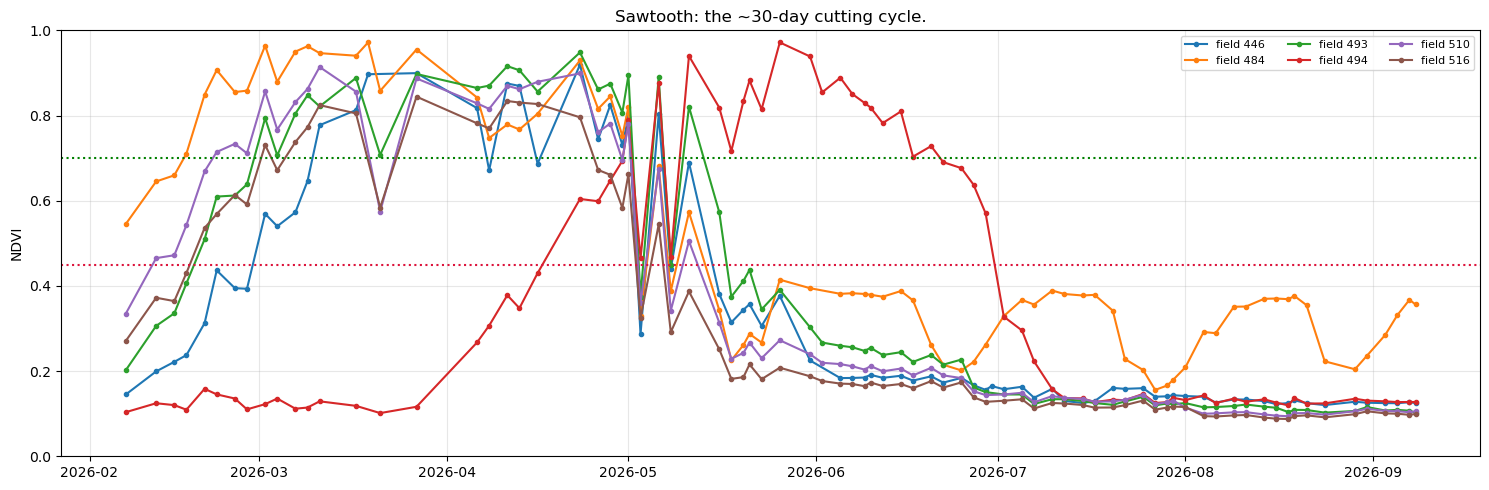

In [23]:
import matplotlib.pyplot as plt

# Pick six fields with the fullest history so the cutting cycle is visible.
if len(HARD):
    pick = list(HARD.field_id.unique()[:6])
else:
    counts = TS.groupby("field_id").ndvi.count().sort_values(ascending=False)
    pick = list(counts.index[:6])

sub = TS[TS.field_id.isin(pick)]
fig, ax = plt.subplots(figsize=(15, 5))
for fid, grp in sub.groupby("field_id"):
    grp = grp.sort_values("date")
    ax.plot(grp["date"], grp["ndvi"], marker="o", ms=3, label="field %d" % fid)
if len(HARD):
    for d in sorted(HARD.emit_date.unique()):
        ax.axvline(pd.Timestamp(d), color="grey", ls="--", alpha=.6)
ax.axhline(LOW, color="crimson", ls=":"); ax.axhline(HIGH, color="green", ls=":")
ax.set_ylim(0, 1); ax.set_ylabel("NDVI"); ax.legend(fontsize=8, ncol=3)
ax.set_title("Sawtooth: the ~30-day cutting cycle." +
             (" Dashed verticals are hyperspectral measurement days." if len(HARD) else ""))
ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("tabarjal_sawtooth.png", dpi=130, bbox_inches="tight")
plt.show()

## 12 · Source record

In [24]:
if len(HARD): HARD.to_csv("tabarjal_hard_set.csv", index=False)
if len(D):    D.to_csv("tabarjal_model_table.csv", index=False)

import sklearn, rasterio
print("DATA")
print("  Sentinel-2 L2A   collection sentinel-2-l2a, Earth Search v1, %d days %s to %s, cloud < %d%%"
      % (len(dates), dates[0], dates[-1], MAX_CLOUD_S2))
if len(HARD):
    print("  EMIT L2A RFL     collection EMITL2ARFL, NASA CMR, %d granules used" % HARD.granule.nunique())
    for g in sorted(HARD.granule.unique()):
        print("                   " + g)
else:
    print("  EMIT L2A RFL     not run in this execution (no Earthdata credentials)")
print()
print("PARAMETERS")
print("  AOI              %s  (EPSG:4326)" % AOI)
print("  projection       %s   field detection %d m   time series %d m" % (UTM, RES_FIELD, RES_TS))
print("  field filter     %d-%d ha, eccentricity <= 0.75, solidity >= 0.85" % (MIN_HA, MAX_HA))
print("  thresholds       LOW %.2f  HIGH %.2f" % (LOW, HIGH))
print("  label window     %d to %d days after the hyperspectral measurement" % (FUTURE_MIN, FUTURE_MAX))
print("  cloud screening  Sentinel-2 SCL classes %s dropped" % SCL_DROP)
print()
print("SOFTWARE  numpy %s | pandas %s | xarray %s | rasterio %s | scikit-learn %s"
      % (np.__version__, pd.__version__, xr.__version__, rasterio.__version__, sklearn.__version__))
print()
print("FILES     tabarjal_fields.geojson, tabarjal_ndvi_series.csv, tabarjal_emit_pooled.csv,")
print("          tabarjal_model_table.csv, tabarjal_hard_set.csv")

DATA
  Sentinel-2 L2A   collection sentinel-2-l2a, Earth Search v1, 82 days 2026-02-07 to 2026-09-08, cloud < 20%
  EMIT L2A RFL     not run in this execution (no Earthdata credentials)

PARAMETERS
  AOI              [38.15, 29.75, 38.85, 30.3]  (EPSG:4326)
  projection       EPSG:32637   field detection 20 m   time series 60 m
  field filter     10-400 ha, eccentricity <= 0.75, solidity >= 0.85
  thresholds       LOW 0.45  HIGH 0.70
  label window     15 to 45 days after the hyperspectral measurement
  cloud screening  Sentinel-2 SCL classes [0, 1, 3, 8, 9, 10, 11] dropped

SOFTWARE  numpy 2.5.3 | pandas 2.3.3 | xarray 2025.10.1 | rasterio 1.5.1 | scikit-learn 1.7.2

FILES     tabarjal_fields.geojson, tabarjal_ndvi_series.csv, tabarjal_emit_pooled.csv,
          tabarjal_model_table.csv, tabarjal_hard_set.csv


## 15 · Write the dashboard data file

The dashboard and the API both read one file. This cell produces it: field polygons, the
season NDVI series as integers (NDVI x 1000, `null` where a date was screened out), the
pooled EMIT measurements, and the metadata the interface labels itself with.

Drop `tabarjal.json` beside `dashboard/index.html` and the interface is live. The same file
is what `api/service.py` loads.

In [25]:
import json, gzip

G4 = G.to_crs(4326).copy()
G4["geometry"] = G4.geometry.simplify(0.0003)          # ~30 m, keeps the circle, halves the bytes

fields = []
for _, r in G4.iterrows():
    g = r.geometry
    poly = g if g.geom_type == "Polygon" else max(g.geoms, key=lambda p: p.area)
    fields.append({"id": int(r.field_id),
                   "ha": round(float(r.area_ha), 1),
                   "c": [round(poly.centroid.x, 5), round(poly.centroid.y, 5)],
                   "p": [[round(x, 5), round(y, 5)] for x, y in poly.exterior.coords]})

order = sorted(TS.date.unique())
dates = [pd.Timestamp(d).strftime("%Y-%m-%d") for d in order]
piv   = TS.pivot_table(index="field_id", columns="date", values="ndvi").reindex(columns=order)

ndvi = {str(int(fid)): [None if pd.isna(v) else int(round(float(v) * 1000)) for v in row.values]
        for fid, row in piv.iterrows()}

em = E.copy() if len(E) else pd.DataFrame(columns=["field_id", "emit_date", "PRI", "NDVI_emit", "NDWI", "REP", "D970"])
if len(em):
    em["emit_date"] = pd.to_datetime(em.emit_date).dt.strftime("%Y-%m-%d")
emit_rows = []
for _, r in em.iterrows():
    keep = lambda v, nd=3: None if pd.isna(v) else round(float(v), nd)
    emit_rows.append({"id": int(r.field_id), "d": r.emit_date,
                      "PRI": keep(r.PRI), "NDVI": keep(r.NDVI_emit), "NDWI": keep(r.NDWI),
                      "REP": keep(r.REP, 1), "D970": keep(r.D970, 4)})

payload = {
    "meta": {"aoi": AOI, "crs": UTM,
             "res_field_m": RES_FIELD, "res_series_m": RES_TS,
             "season": [dates[0], dates[-1]],
             "n_fields": len(fields), "n_days": len(dates), "n_obs": int(len(TS)),
             "ha_total": round(float(G.area_ha.sum()), 1),
             "ha_median": round(float(G.area_ha.median()), 1),
             "low": LOW, "high": HIGH,
             "emit_scenes": sorted(em.emit_date.unique().tolist()) if len(em) else [],
             "emit_granules": sorted(HARD.granule.unique().tolist()) if len(HARD) else []},
    "dates": dates, "fields": fields, "ndvi": ndvi, "emit": emit_rows,
}

raw = json.dumps(payload, separators=(",", ":")).encode()
open("tabarjal.json", "wb").write(raw)
with gzip.open("tabarjal.json.gz", "wb") as fh:                # the API reads the gzipped copy
    fh.write(raw)

print("tabarjal.json     %8.1f KB" % (len(raw) / 1024))
print("fields %d | dates %d | ndvi rows %d | emit rows %d"
      % (len(fields), len(dates), len(ndvi), len(emit_rows)))
print()
print("NEXT  - download tabarjal.json and put it beside dashboard/index.html,")
print("        then serve that folder:  python3 -m http.server 8000")
print("      - for the API, put tabarjal.json.gz in data/ and run:")
print("        uvicorn api.service:app --reload")
if not emit_rows:
    print()
    if not HAVE_EDL:
        print("Note: no Earthdata credentials were found, so the hyperspectral section")
        print("      was skipped and that panel will be empty.")
    else:
        print("Note: credentials were present but no EMIT rows survived - check the")
        print("      granule-matching output above for why.")
    print("      Nothing in the ranking depends on it either way.")

tabarjal.json        326.7 KB
fields 518 | dates 82 | ndvi rows 518 | emit rows 0

NEXT  - download tabarjal.json and put it beside dashboard/index.html,
        then serve that folder:  python3 -m http.server 8000
      - for the API, put tabarjal.json.gz in data/ and run:
        uvicorn api.service:app --reload

Note: no Earthdata credentials were found, so the hyperspectral section
      was skipped and that panel will be empty.
      Nothing in the ranking depends on it either way.
